# 09. Load and Preprocess Images

This tutorial shows how to load and preprocess an image dataset in three ways:

* First, you will use high-level Keras preprocessing utilities (such as `tf.keras.utils.image_dataset_from_directory`) and layers (`tf.keras.layers.Rescaling`) to read a directory of images on disk.
* Next, you will write your own input pipeline from scratch using tf.data.
* Finally, you will download a dataset from the large catalog available in TensorFlow datasets.

### Setup

In [2]:
import numpy as np
import os
import PIL
import PIL.Image
import tensorflow as tf
import tensorflow_datasets as tfds

In [3]:
print(tf.__version__)

2.21.0


**Download the flowers dataset**

This tutorial uses a dataset of several thousand photos of flowers. The flowers dataset contains five sub-directories, one per class:

```
flowers_photos/
  daisy/
  dandelion/
  roses/
  sunflowers/
  tulips/
```

In [5]:
import pathlib
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = tf.keras.utils.get_file(origin=dataset_url, extract=True)
data_dir = pathlib.Path(archive).with_suffix('')

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 31s 0us/step


After downloading (218 MB), you should now have a copy of the flow photos available. There are 3,670 total images:

In [12]:
archive

'C:\\Users\\yigit\\.keras\\datasets\\flower_photos.tgz'

In [7]:
data_dir

WindowsPath('C:/Users/yigit/.keras/datasets/flower_photos')

In [11]:
type(data_dir)

pathlib._local.WindowsPath

In [28]:
data_dir_actual = pathlib.Path("C:/Users/yigit/.keras/datasets/flower_photos.tgz/flower_photos/")

# image_count = len(list(data_dir.glob('*/*.jpg')))
image_count = len(list(data_dir_actual.glob('*/*.jpg')))
print(image_count)   # It must've shown 3670

3670


In [29]:
os.listdir(archive+'/flower_photos')

['daisy', 'dandelion', 'LICENSE.txt', 'roses', 'sunflowers', 'tulips']

Each directory contains images of that type of flower. Here are some roses:

C:\Users\yigit\.keras\datasets\flower_photos.tgz\flower_photos\roses\10090824183_d02c613f10_m.jpg


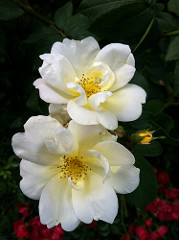

In [30]:
roses = list(data_dir_actual.glob('roses/*'))
print(roses[0])
PIL.Image.open(str(roses[0]))

C:\Users\yigit\.keras\datasets\flower_photos.tgz\flower_photos\roses\102501987_3cdb8e5394_n.jpg


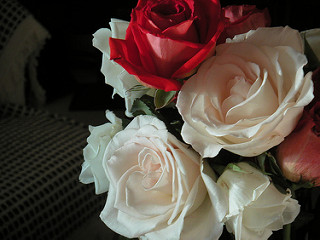

In [32]:
print(roses[1])
PIL.Image.open(str(roses[1]))

### Load data using a Keras utility

Let's load these images off disk using the helpful `tf.keras.utils.image_dataset_from_directory` utility.

**Create a dataset**

Define some parameters for the loader:

In [33]:
batch_size = 32
img_height = 180
img_width = 180

It's good practice to use a validation split when developing your model. You will use 80% of the images for training and 20% for validation.

In [35]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir_actual,
    validation_split=0.2,
    subset='training',
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [36]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir_actual,
    validation_split=0.2,
    subset='validation',
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.


You can find the class names in the `class_names` attribute on these datasets.

In [37]:
class_names = train_ds.class_names
print(class_names)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


**Visualize the data**

Here are the first nine images from the training dataset.

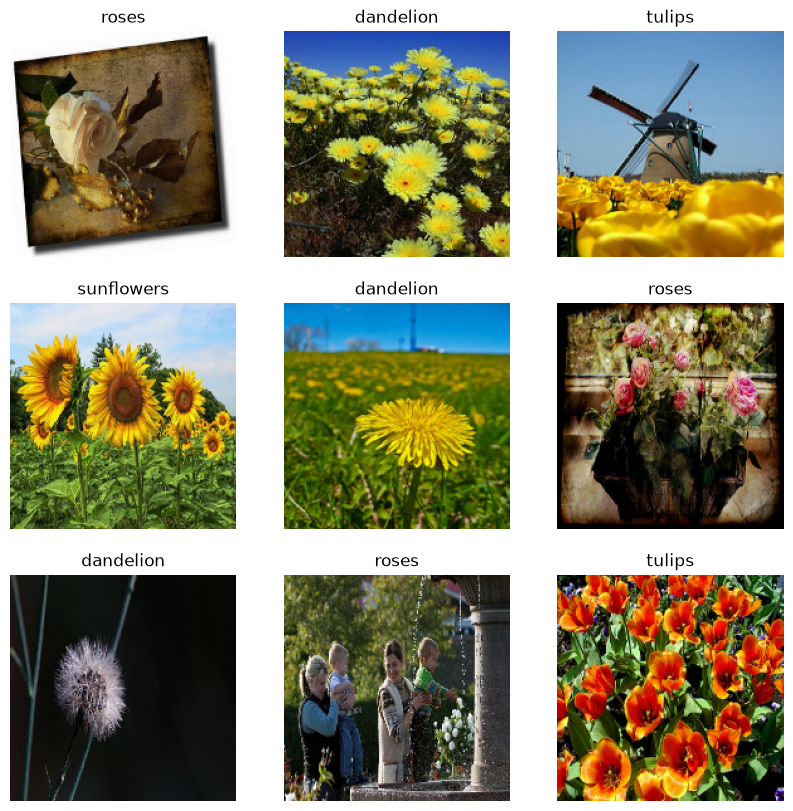

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

You can train a model using these datasets by passing them to `model.fit`. If you like, you can also manually iterate over the dataset and retrieve batches of images:

In [39]:
for image_batch, labels_batch in train_ds:
    print(image_batch.shape)
    print(labels_batch.shape)
    break

(32, 180, 180, 3)
(32,)


The `image_batch` is a tensor of the shape `(32, 180, 180, 3)`. This is a batch of 32 images of shape `180x180x3` (the last dimension refers to color channels RGB). The `label_batch` is a tensor of the shape `(32,)`, these are corresponding label to the 32 images.

You can call `.numpy()` on either of these tensors to convert them to a `numpy.ndarray`.

**Standardize the data**

The RGB channel values are in the `[0, 255]` range. This is not ideal for a neural network; in general you should seek to make your input values small.

Here, you will standardize values to be in the `[0, 1]` range by using `tf.keras.layers.Rescaling`:

In [40]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

There are two ways to use this layer. You can apply it to the dataset by calling `Dataset.map`:

In [42]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in '[0, 1]'.
print(np.min(first_image), np.max(first_image))

0.0 0.96902645


Or, you can include the layer inside your model definition to simplify deployment. You will use the second approach here.

**Note:** If you would like to scale pixel values to [-1,1] you can instead write `tf.keras.layers.Rescaling(1./127.5, offset=-1)`

**Note:** You previously resized images using the `image_size`argument of `tf.keras.utils.image_dataset_from_directory`. If you want to include the resizing logic in your model as well, you can use the `tf.keras.layers.Resizing` layer.

**Configure the dataset for performance**

Let's make sure to use buffered prefetching so you can yield data from disk without hacing I/O become blocking. These are two important methods you should use when loading data:

* `Dataset.cache` keeps the images in memory after they're loaded off disk during the first epoch. This will ensure the dataset does not become a bottleneck while training your model. If your dataset is too large to fit into memory, you can also use this method to create a performant on-disk cache.

* `Dataset.prefetch` overlaps data preprocessing and model execution while training.

Interested readers can learn more about botht methods, as well as how to cache data to disk in the Prefetching section of the Better performance with the tf.data API guide.

In [44]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

**Train a model**

For completeness, you will show how to train a simple model using the datasets you have just prepared.

The Sequential model consists of three convolution blocks (`tf.keras.layers.Conv2D`) with a max pooling layer (`tf.keras.layers.MaxPooling2D`) in each of them. There's a fully-connected layer (`tf.keras.layers.Dense`) with 128 units on top of it that is activation by a ReLU activation function (`relu`). This model has not been tuned in any way - the goal is to show you the mechanics using the datasets you just created. To learn more about image classification, visit the Image classification tutorial.

In [45]:
num_classes = 5

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(num_classes)
])

Choose the `tf.keras.optimizers.Adam` optimizer and `tf.keras.losses.SparseCategoricalCrossentropy` loss function. To view training and validation accuracy for each training epoch, pass the `metrics` argument to `Model.compile`.

In [46]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'])

In [47]:
model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3


C:\Users\yigit\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 237ms/step - accuracy: 0.4104 - loss: 1.3239 - val_accuracy: 0.5232 - val_loss: 1.1271
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 202ms/step - accuracy: 0.5899 - loss: 1.0322 - val_accuracy: 0.5627 - val_loss: 1.0525
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 203ms/step - accuracy: 0.6655 - loss: 0.8568 - val_accuracy: 0.5913 - val_loss: 0.9764


You may notice the validation accuracy is low compared to the training accuracy, indicating your model is overfitting.

### Using tf.data for finer control

The above Keras preprocessing utility - `tf.keras.utils.image_dataset_from_directory` - is a convenient way to create a `tf.data.Dataset` from a directory of images.

For finer grain control, you can write your own input pipeline using `tf.data`. This section shows how to do just that, beginning with the file paths from the TGZ file you downloaded earlier.

In [49]:
list_ds = tf.data.Dataset.list_files(str(data_dir_actual/'*/*'), shuffle=False)
list_ds = list_ds.shuffle(image_count, reshuffle_each_iteration=False)

In [50]:
list_ds

<_ShuffleDataset element_spec=TensorSpec(shape=(), dtype=tf.string, name=None)>

In [51]:
for f in list_ds.take(5):
    print(f.numpy())

b'C:\\Users\\yigit\\.keras\\datasets\\flower_photos.tgz\\flower_photos\\dandelion\\4571681134_b605a61547_n.jpg'
b'C:\\Users\\yigit\\.keras\\datasets\\flower_photos.tgz\\flower_photos\\tulips\\13562271714_d534531374.jpg'
b'C:\\Users\\yigit\\.keras\\datasets\\flower_photos.tgz\\flower_photos\\roses\\14312910041_b747240d56_n.jpg'
b'C:\\Users\\yigit\\.keras\\datasets\\flower_photos.tgz\\flower_photos\\dandelion\\16096748028_7876887ab2.jpg'
b'C:\\Users\\yigit\\.keras\\datasets\\flower_photos.tgz\\flower_photos\\daisy\\2473825306_62fd5f8785_n.jpg'


The tree structure of the files can be used to compile a `class_names` list.

In [54]:
class_names = np.array(sorted([item.name for item in data_dir_actual.glob('*') if item.name != "LICENSE.txt"]))
print(class_names)

['daisy' 'dandelion' 'roses' 'sunflowers' 'tulips']


Split the dataset into training and validation sets:

In [55]:
val_size = int(image_count * 0.2)
train_ds = list_ds.skip(val_size)
val_ds = list_ds.take(val_size)

You can print the length of each dataset as follows:

In [56]:
print(tf.data.experimental.cardinality(train_ds).numpy())
print(tf.data.experimental.cardinality(val_ds).numpy())

2936
734


Write a short function that converts a file path to an `(img, label)` pair:

In [57]:
def get_label(file_path):
    # Convert the path to a list of path components
    parts = tf.strings.split(file_path, os.path.sep)
    # The second to last is the class-directory
    one_hot = parts[-2] == class_names
    # Integer encode the label
    return tf.argmax(one_hot)

In [58]:
def decode_img(img):
    # Convert the compressed string to a 3D unit8 tensor
    img = tf.io.decode_jpeg(img, channels=3)
    # Resize the image to the desired size
    return tf.image.resize(img, [img_height, img_width])

In [59]:
def process_path(file_path):
    label = get_label(file_path)
    # Load the raw data from the file as a string
    img = tf.io.read_file(file_path)
    img = decode_img(img)
    return img, label

Use `Dataset.map` to create a dataset of `image, label` pairs:

In [60]:
# Set 'num_parallel_calls' so multiple images are loaded/processed in parallel.
train_ds = train_ds.map(process_path, num_parallel_calls=AUTOTUNE)
val_ds = val_ds.map(process_path, num_parallel_calls=AUTOTUNE)

In [62]:
for image, label in train_ds.take(1):
    print("Image shape: ", image.numpy().shape)
    print("Label: ", label.numpy())

Image shape:  (180, 180, 3)
Label:  2


**Configure dataset for performance**

To train a model with this dataset, you will want the data:

* To be well shuffled.
* To be batched.
* Batches to be available as soon as possible.

These features can be added using the `tf.data` API. For more details, visit the Input Pipeline Performance guide.

In [63]:
def configure_for_performance(ds):
    ds = ds.cache()
    ds = ds.shuffle(buffer_size=1000)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(buffer_size=AUTOTUNE)
    return ds

train_ds = configure_for_performance(train_ds)
val_ds = configure_for_performance(val_ds)

**Visualize the data**

You can visualize this dataset similarly to the one you created previously:

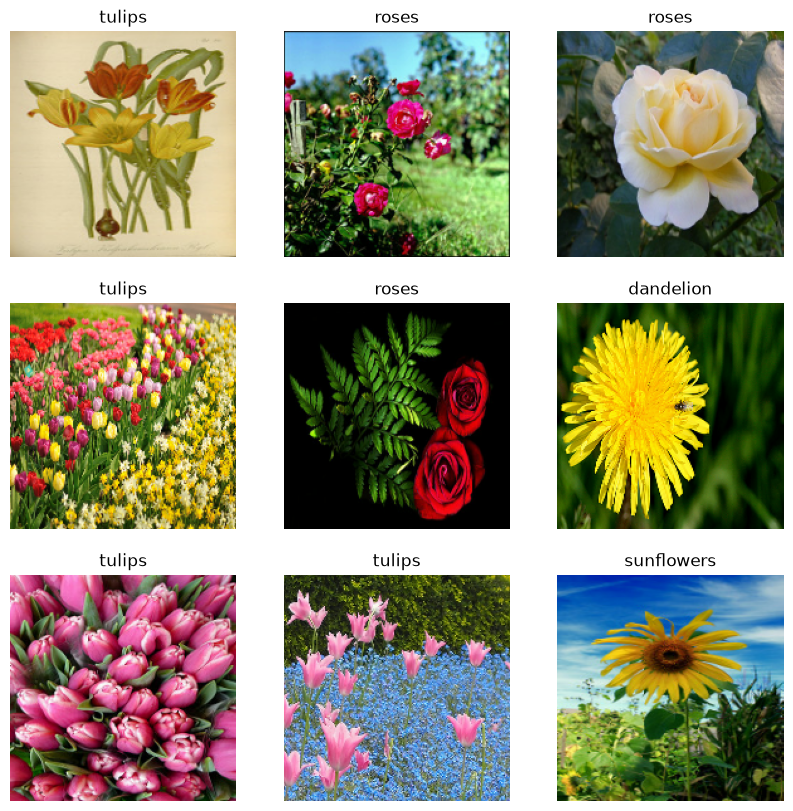

In [65]:
image_batch, label_batch = next(iter(train_ds))

plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i+1)
    plt.imshow(image_batch[i].numpy().astype("uint8"))
    label = label_batch[i]
    plt.title(class_names[label])
    plt.axis("off")

**Continue training the model**

You have now manually built a similar `tf.data.Dataset` to the one created by `tf.keras.utils.image_dataset_from_directory` above. You can continue training the model with it. As before, you will traing for just a few epochs to keep the running time short.

In [66]:
model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 218ms/step - accuracy: 0.7030 - loss: 0.7544 - val_accuracy: 0.7180 - val_loss: 0.7772
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 203ms/step - accuracy: 0.7687 - loss: 0.6033 - val_accuracy: 0.7316 - val_loss: 0.7594
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 204ms/step - accuracy: 0.8498 - loss: 0.4079 - val_accuracy: 0.7016 - val_loss: 0.8543


### Using TensorFlow Datasets

So far, this tutorial has focused on loading data off disk. You can also find a dataset to use by exploring the large catalog of easy-to-download datasets at TensforFlow Datasets.

As you have previously loaded the Flowers dataset off disk, let's now import it with TensorFlow Datasets.

Download the Flowers dataset using TensorFlow Datasets:

In [67]:
(train_ds, val_ds, test_ds), metadata = tfds.load(
    'tf_flowers',
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
    with_info=True,
    as_supervised=True,
)

C:\Users\yigit\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Dl Completed...: 0 url [00:00, ? url/s]
Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]
Generating train examples...: 0 examples [00:00, ? examples/s]
Generating train examples...: 751 examples [00:01, 750.68 examples/s]
Generating train examples...: 1502 examples [00:02, 687.55 examples/s]
Generating train examples...: 2259 examples [00:03, 717.49 examples/s]
Generating train examples...: 3067 examples [00:04, 751.90 examples/s]
                                                                      
Shuffling C:\Users\yigit\tensorflow_datasets\tf_flowers\incomplete.PUZ2IK_3.0.1\tf_flowers-train.tfrecord-[0-9][0-9][0-9][0-9][0-9]-of-[0-9][0-9][0-9][0-9][0-9]...:   0%|          | 0/3670 [00:00<?, ?

Dataset tf_flowers downloaded and prepared to C:\Users\yigit\tensorflow_datasets\tf_flowers\3.0.1. Subsequent calls will reuse this data.


The flowers dataset has five classes:

In [68]:
num_classes = metadata.features['label'].num_classes
print(num_classes)

5


Retrieve an image from the dataset:

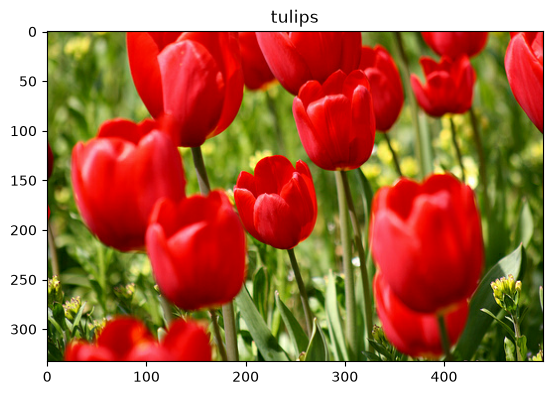

In [69]:
get_label_name = metadata.features['label'].int2str

image, label = next(iter(train_ds))
_ = plt.imshow(image)
_ = plt.title(get_label_name(label))

As before, remember to batch, shuffle, and configure the training, validation, and test sets for performance:

In [70]:
train_ds = configure_for_performance(train_ds)
val_ds = configure_for_performance(val_ds)
test_ds = configure_for_performance(test_ds)

You can find a complete example of working with the Flowers dataset and TensorFlow Datasets by visiting the Data augmentation tutorial.

### Next Steps

This tutorial showed two ways of loading images off disk. First, you learned how to load and preprocess an image dataset using Keras preprocessing layers and utilities. Next, you learned how to write an input pipeline from scratch using `tf.data`. Finally, you learned how to download a dataset from TensorFlow Datasets.

For your next stesp:

* You can learn how to add data augmentation.
* To learn more about `tf.data`, you can visit the tf.data: Build TensorFlow input pipelines guide.